In [1]:
from google.colab import files
uploaded = files.upload()  # Select AR_Hairstyle_TryOn_Backup.zip


Saving AR_Hairstyle_TryOn_Backup.zip to AR_Hairstyle_TryOn_Backup.zip


In [2]:
!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 99.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 49.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 105.9 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

In [3]:
from ultralytics import YOLO

# Load the available model
model = YOLO("AR_project_backup/yolov8l.pt")  # or use "yolov11.pt" if that’s your desired model



Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


100%|██████████| 83.7M/83.7M [00:00<00:00, 99.9MB/s]


In [4]:
from google.colab import files
uploaded = files.upload()


Saving face_img.jpg to face_img.jpg


In [5]:
import os
os.listdir()


['.config',
 'AR_Hairstyle_TryOn_Backup.zip',
 'AR_project_backup',
 'face_img.jpg',
 'sample_data']

In [6]:
results = model("face_img.jpg")[0]  # Assuming it's in the root directory



image 1/1 /content/face_img.jpg: 640x448 1 person, 57.6ms
Speed: 14.4ms preprocess, 57.6ms inference, 362.9ms postprocess per image at shape (1, 3, 640, 448)


In [7]:
import shutil
shutil.move("face_img.jpg", "AR_project_backup/face_img.jpg")


'AR_project_backup/face_img.jpg'


image 1/1 /content/AR_project_backup/face_img.jpg: 640x448 1 person, 45.9ms
Speed: 2.5ms preprocess, 45.9ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 448)


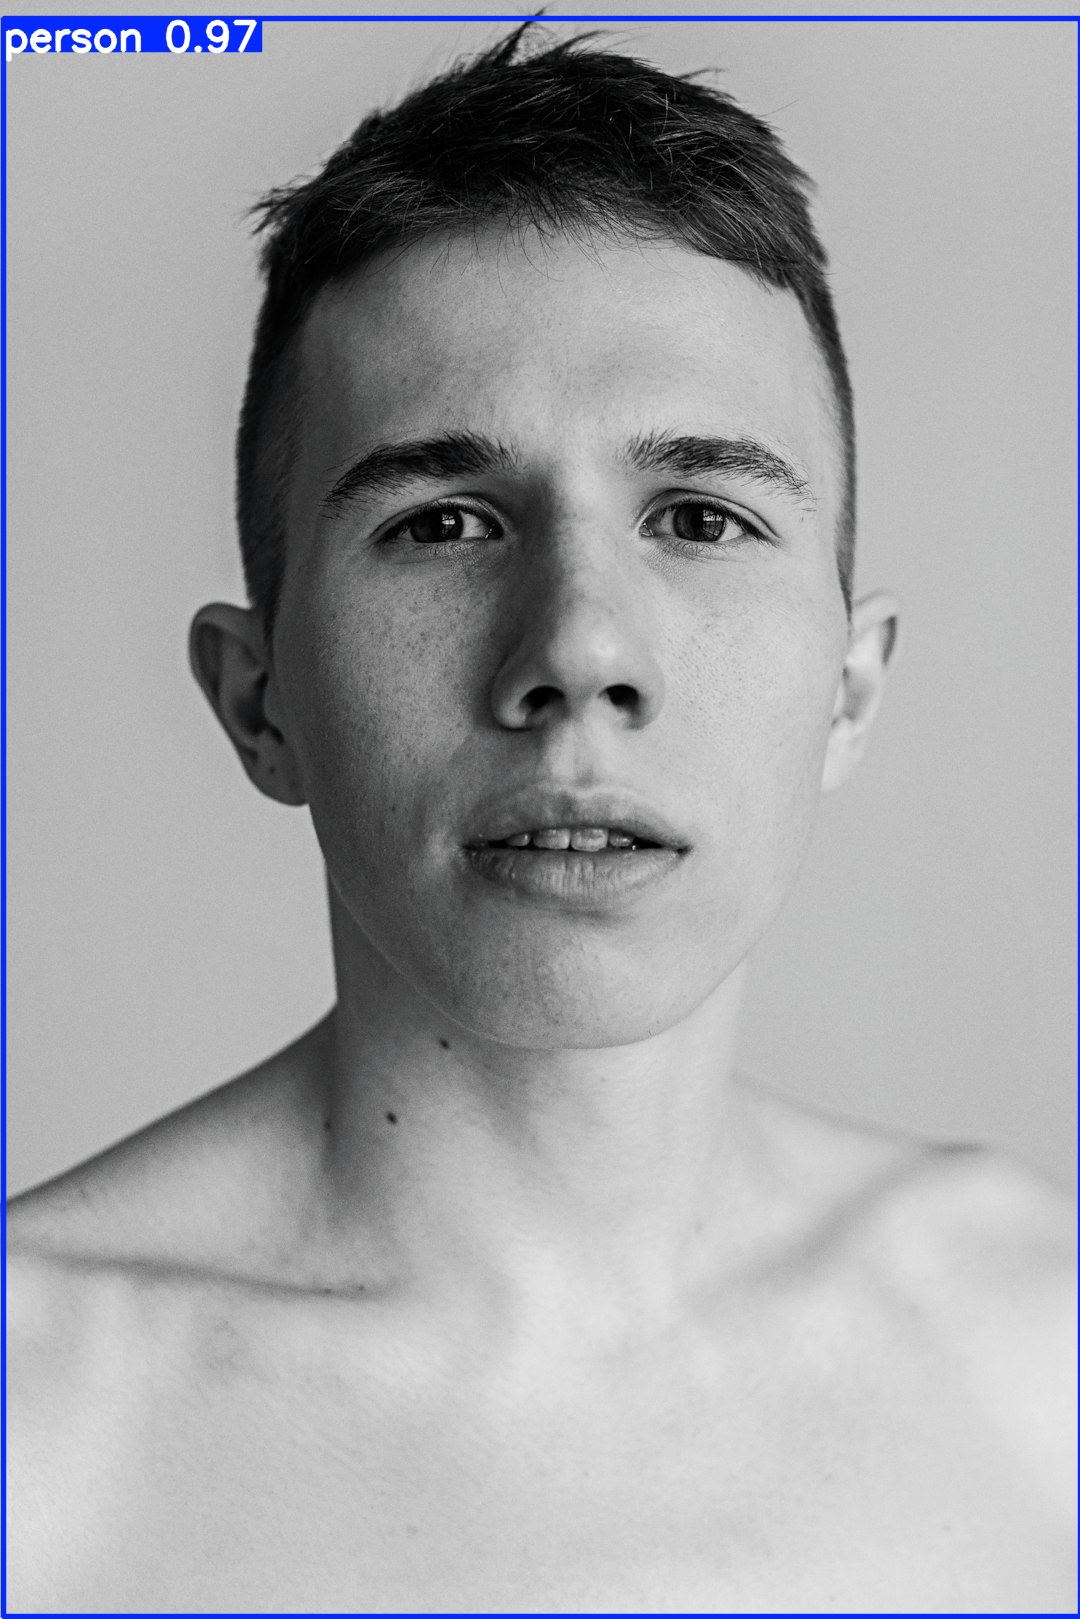

In [8]:
results = model("AR_project_backup/face_img.jpg")[0]
results.show()



In [9]:
import matplotlib.pyplot as plt
import cv2
import os
from glob import glob

# Save the inference result (make sure 'results' is a valid detection output)
results.save()

# Check available prediction folders
prediction_dirs = sorted(glob("runs/detect/predict*"))

if len(prediction_dirs) == 0:
    print("❌ No prediction folder found. Check if `results.save()` worked.")
else:
    latest_dir = prediction_dirs[-1]
    print(f"✅ Found latest prediction folder: {latest_dir}")

    # Find all saved images inside that folder
    image_files = glob(os.path.join(latest_dir, "*.jpg"))

    if len(image_files) == 0:
        print("❌ No images found in the prediction folder.")
    else:
        saved_image_path = image_files[0]
        print(f"📷 Showing image: {saved_image_path}")

        img = cv2.imread(saved_image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.imshow(img)
        plt.axis('off')
        plt.title("YOLOv8 Detection Output")
        plt.show()



❌ No prediction folder found. Check if `results.save()` worked.


In [10]:
# Run detection and inspect results
results = model("AR_project_backup/face_img.jpg")[0]  # get first result
results = model("AR_project_backup/face_img.jpg")[0]

# Print detected class IDs and bounding boxes
print("Boxes:", results.boxes)
print("Class IDs:", results.boxes.cls)
print("Confidence Scores:", results.boxes.conf)
print("Class Names:", [model.names[int(cls)] for cls in results.boxes.cls])




image 1/1 /content/AR_project_backup/face_img.jpg: 640x448 1 person, 45.9ms
Speed: 2.6ms preprocess, 45.9ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 448)

image 1/1 /content/AR_project_backup/face_img.jpg: 640x448 1 person, 45.8ms
Speed: 2.8ms preprocess, 45.8ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 448)
Boxes: ultralytics.engine.results.Boxes object with attributes:

cls: tensor([0.], device='cuda:0')
conf: tensor([0.9745], device='cuda:0')
data: tensor([[3.0555e+00, 1.8295e+01, 1.0800e+03, 1.6163e+03, 9.7449e-01, 0.0000e+00]], device='cuda:0')
id: None
is_track: False
orig_shape: (1619, 1080)
shape: torch.Size([1, 6])
xywh: tensor([[ 541.5278,  817.3061, 1076.9445, 1598.0226]], device='cuda:0')
xywhn: tensor([[0.5014, 0.5048, 0.9972, 0.9870]], device='cuda:0')
xyxy: tensor([[   3.0555,   18.2948, 1080.0000, 1616.3174]], device='cuda:0')
xyxyn: tensor([[0.0028, 0.0113, 1.0000, 0.9983]], device='cuda:0')
Class IDs: tensor([0.], device='cuda:0')

In [11]:
from google.colab import files
uploaded = files.upload()  # Upload your PNG hairstyle image


Saving hairstyle2.png to hairstyle2.png


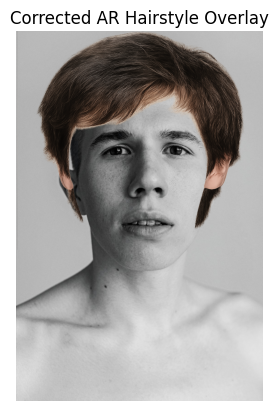

In [13]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Load image and PNG hairstyle
base_img = cv2.imread("AR_project_backup/face_img.jpg")
base_img = cv2.cvtColor(base_img, cv2.COLOR_BGR2RGB)

# Load PNG with transparency
hairstyle = Image.open("hairstyle2.png").convert("RGBA")

# Get YOLOv8 face/person bounding box
x1, y1, x2, y2 = results.boxes.xyxy[0].cpu().numpy().astype(int)
box_w, box_h = x2 - x1, y2 - y1

# Resize hairstyle to match width of face, and adjust height to look natural
overlay = hairstyle.resize((box_w + 30, int(box_h * 0.6)))
overlay_np = np.array(overlay)

# Determine position: slightly above detected top (y1), centered on x-axis
overlay_h, overlay_w = overlay_np.shape[:2]
x_offset = x1 - (overlay_w - box_w) // 2
y_offset = y1 - overlay_h + 10  # shift slightly above the head

# Boundary check to avoid image clipping
x_offset = max(0, x_offset)
y_offset = max(0, y_offset)
x_end = min(base_img.shape[1], x_offset + overlay_w)
y_end = min(base_img.shape[0], y_offset + overlay_h)

# Adjust overlay size if clipping occurs
overlay_crop = overlay_np[0:(y_end - y_offset), 0:(x_end - x_offset)]

# Extract alpha and RGB channels
alpha = overlay_crop[:, :, 3] / 255.0
rgb_overlay = overlay_crop[:, :, :3]

# Perform blending
for c in range(3):
    base_img[y_offset:y_end, x_offset:x_end, c] = (
        alpha * rgb_overlay[:, :, c] +
        (1 - alpha) * base_img[y_offset:y_end, x_offset:x_end, c]
    )

# Show result
plt.imshow(base_img)
plt.axis('off')
plt.title("Corrected AR Hairstyle Overlay")
plt.show()



In [14]:
!pip install mediapipe --quiet


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.6/35.6 MB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 102.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 24.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.12.0 requires protobuf<6.0.0,>=5.29.1, but you have protobuf 4.25.8 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
grpcio-status 1.71.0 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 4.25.8 which is incompatible.


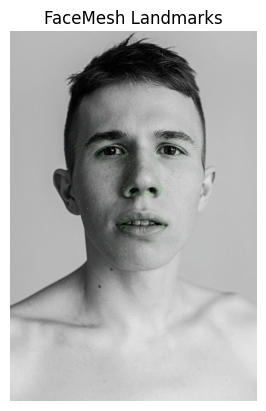

In [15]:
import mediapipe as mp
import cv2
import matplotlib.pyplot as plt

mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(static_image_mode=True)

# Read your image
img_path = "AR_project_backup/face_img.jpg"
image = cv2.imread(img_path)
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Detect facial landmarks
results = face_mesh.process(rgb_image)

# Draw landmarks
if results.multi_face_landmarks:
    annotated = image.copy()
    for landmarks in results.multi_face_landmarks:
        for id, lm in enumerate(landmarks.landmark):
            x, y = int(lm.x * image.shape[1]), int(lm.y * image.shape[0])
            cv2.circle(annotated, (x, y), 1, (0, 255, 0), -1)
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.title("FaceMesh Landmarks")
    plt.axis('off')
    plt.show()
else:
    print("❌ No face detected")


In [16]:
img_path = "AR_project_backup/face_img.jpg"
image = cv2.imread(img_path)
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

results = face_mesh.process(rgb_image)



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


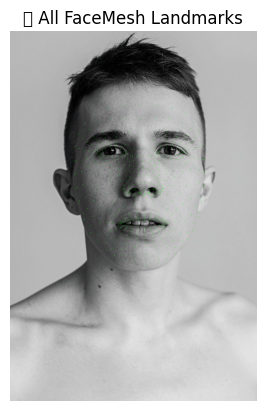

In [17]:
if results.multi_face_landmarks:
    annotated = image.copy()
    for landmarks in results.multi_face_landmarks:
        for id, lm in enumerate(landmarks.landmark):
            x, y = int(lm.x * image.shape[1]), int(lm.y * image.shape[0])
            cv2.circle(annotated, (x, y), 1, (0, 255, 0), -1)
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.title("🟢 All FaceMesh Landmarks")
    plt.axis('off')
    plt.show()



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


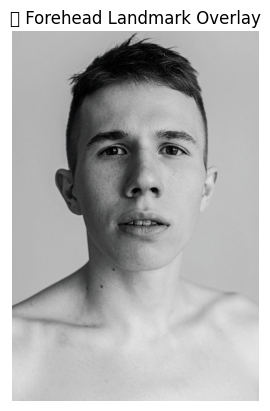

In [18]:
# Extended forehead + hairline region landmarks
landmark_ids = [10, 67, 107, 151, 297, 336, 338]

forehead_coords = []

for face_landmarks in results.multi_face_landmarks:
    for idx in landmark_ids:
        lm = face_landmarks.landmark[idx]
        x = int(lm.x * image.shape[1])
        y = int(lm.y * image.shape[0])
        forehead_coords.append((x, y))


plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("🔵 Forehead Landmark Overlay")
plt.axis('off')
plt.show()


In [19]:
import os
os.listdir()


['.config',
 'results_face_img.jpg',
 'AR_Hairstyle_TryOn_Backup.zip',
 'AR_project_backup',
 'hairstyle2.png',
 'sample_data']

In [20]:
image_path = "face_img.jpg"


In [21]:
image_path = "AR_project_backup/face_img.jpg"


In [22]:
image = cv2.imread(image_path)
if image is None:
    print("Image not loaded! Check the path and file name.")
else:
    print("Image loaded successfully.")


Image loaded successfully.


In [23]:
import os

image_path = "face_img.jpg"
if not os.path.exists(image_path):
    print(f"File '{image_path}' does not exist in the current directory!")
else:
    image = cv2.imread(image_path)
    if image is None:
        print("Image couldn't be loaded. Check the file format and integrity.")
    else:
        rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        print("Image loaded and converted successfully.")


File 'face_img.jpg' does not exist in the current directory!


In [24]:
from google.colab import files
uploaded = files.upload()


Saving face_img.jpg to face_img.jpg


In [25]:
import os
os.listdir()


['.config',
 'results_face_img.jpg',
 'AR_Hairstyle_TryOn_Backup.zip',
 'AR_project_backup',
 'hairstyle2.png',
 'face_img.jpg',
 'sample_data']

In [26]:
import cv2
import mediapipe as mp

# Initialize Mediapipe FaceMesh
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(static_image_mode=True)

# Load image using OpenCV
image_path = "face_img.jpg"
image = cv2.imread(image_path)
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Get facial landmarks
results = face_mesh.process(rgb_image)
if results.multi_face_landmarks:
    # Assuming only one face detected
    face_landmarks = results.multi_face_landmarks[0]
    coords = []
    for landmark in face_landmarks.landmark:
        x = int(landmark.x * image.shape[1])
        y = int(landmark.y * image.shape[0])
        coords.append((x, y))
else:
    print("No face detected!")
    coords = []  # To avoid further errors


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


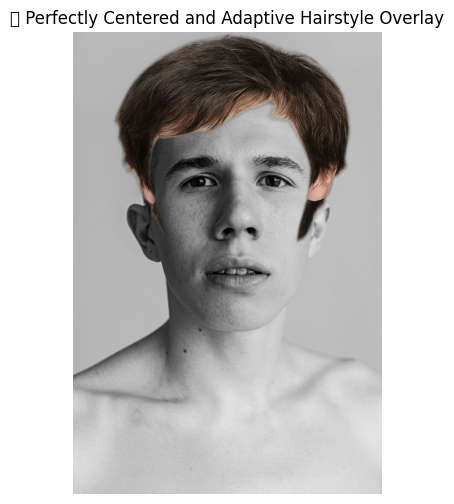

In [1]:
# Install dependencies
!pip install mediapipe==0.10.5 opencv-python pillow

# Imports
import cv2
import mediapipe as mp
import numpy as np
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt

# Load image
image_path = "AR_project_backup/face_img.jpg"
image = cv2.imread(image_path)
if image is None:
    raise FileNotFoundError(f"Image '{image_path}' not found.")
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Initialize MediaPipe FaceMesh
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(static_image_mode=True)

# Detect facial landmarks
results = face_mesh.process(rgb_image)
if not results.multi_face_landmarks:
    raise ValueError("No face detected in the image.")

face_landmarks = results.multi_face_landmarks[0]
coords = [(int(lm.x * image.shape[1]), int(lm.y * image.shape[0])) for lm in face_landmarks.landmark]

# Load hairstyle image
hair_png = Image.open("hairstyle2.png").convert("RGBA")
base_img = Image.open(image_path).convert("RGBA")

# Forehead landmarks
center_top = coords[10]  # Forehead center landmark
left_temple = coords[127]
right_temple = coords[356]

# Dynamic scaling and rotation
forehead_width = int(np.linalg.norm(np.array(right_temple) - np.array(left_temple)))
hair_width = int(forehead_width * 1.8)  # Reduced width scaling for better horizontal fit
hair_height = int(hair_width * hair_png.height / hair_png.width * 0.8)  # Slight height reduction

dx = right_temple[0] - left_temple[0]
dy = right_temple[1] - left_temple[1]
angle = np.degrees(np.arctan2(dy, dx))

# Resize and rotate hairstyle
resized_hair = hair_png.resize((hair_width, hair_height)).rotate(-angle, expand=True)

# Blur alpha channel for smooth blending
blurred_alpha = resized_hair.split()[3].filter(ImageFilter.GaussianBlur(radius=4))
soft_hair = resized_hair.copy()
soft_hair.putalpha(blurred_alpha)

# Calculate placement offsets
adjustment_x = center_top[0] - resized_hair.size[0] // 2
adjustment_y = center_top[1] - resized_hair.size[1] // 2 - 60  # Increased upward shift for natural fit

# Boundary checks with adaptive resizing if needed
if adjustment_x < 0 or adjustment_x + resized_hair.size[0] > base_img.width:
    # Reduce hair width to fit within bounds
    new_width = min(resized_hair.size[0], base_img.width - 20)
    hair_height = int(new_width * resized_hair.size[1] / resized_hair.size[0])
    resized_hair = resized_hair.resize((new_width, hair_height))
    blurred_alpha = resized_hair.split()[3].filter(ImageFilter.GaussianBlur(radius=4))
    soft_hair = resized_hair.copy()
    soft_hair.putalpha(blurred_alpha)
    adjustment_x = max(0, center_top[0] - resized_hair.size[0] // 2)

adjustment_x = np.clip(adjustment_x, 0, base_img.width - resized_hair.width)
adjustment_y = np.clip(adjustment_y, 0, base_img.height - resized_hair.height)

# Final overlay preparation
overlay_layer = Image.new("RGBA", base_img.size)
overlay_layer.paste(soft_hair, (adjustment_x, adjustment_y), mask=soft_hair)

# Final composite
final = Image.alpha_composite(base_img, overlay_layer)

# Show result
plt.figure(figsize=(6, 6))
plt.imshow(final)
plt.axis('off')
plt.title("✨ Perfectly Centered and Adaptive Hairstyle Overlay")
plt.show()





/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


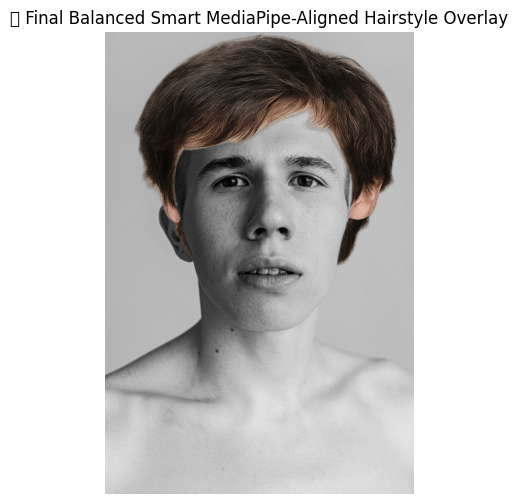

In [3]:
# Install dependencies
!pip install mediapipe opencv-python pillow

# Imports
import cv2
import mediapipe as mp
import numpy as np
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt

# Load image
image_path = "AR_project_backup/face_img.jpg"
image = cv2.imread(image_path)
if image is None:
    raise FileNotFoundError(f"Image '{image_path}' not found.")
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Initialize MediaPipe FaceMesh
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(static_image_mode=True)

# Detect facial landmarks
results = face_mesh.process(rgb_image)
if not results.multi_face_landmarks:
    raise ValueError("No face detected in the image.")

face_landmarks = results.multi_face_landmarks[0]
coords = [(int(lm.x * image.shape[1]), int(lm.y * image.shape[0])) for lm in face_landmarks.landmark]

# Load hairstyle image
hair_png = Image.open("hairstyle2.png").convert("RGBA")
base_img = Image.open(image_path).convert("RGBA")

# Forehead landmarks
center_top = coords[10]
left_temple = coords[127]
right_temple = coords[356]

# Calculate dynamic scaling and rotation
forehead_width = int(np.linalg.norm(np.array(right_temple) - np.array(left_temple)))
hair_width = int(forehead_width * 2.0)  # Balanced width scaling factor
hair_height = int(hair_width * hair_png.height / hair_png.width * 0.8)  # Slight height reduction

dx = right_temple[0] - left_temple[0]
dy = right_temple[1] - left_temple[1]
angle = np.degrees(np.arctan2(dy, dx))

# Resize and rotate hairstyle
resized_hair = hair_png.resize((hair_width, hair_height)).rotate(-angle, expand=True)

# Blur alpha channel for soft edges
blurred_alpha = resized_hair.split()[3].filter(ImageFilter.GaussianBlur(radius=2))
soft_hair = resized_hair.copy()
soft_hair.putalpha(blurred_alpha)

# Final placement adjustments for balance
adjustment_x = -20  # Shift left to reduce right-side bulge
adjustment_y = -100  # Move up to align with forehead

x_offset = center_top[0] - hair_width // 2 + adjustment_x
y_offset = center_top[1] - hair_height // 2 + adjustment_y

# Boundary checks
x_offset = max(0, x_offset)
y_offset = max(0, y_offset)
x_end = min(base_img.width, x_offset + resized_hair.width)
y_end = min(base_img.height, y_offset + resized_hair.height)

# Crop overlay to fit image boundaries
resized_hair = resized_hair.crop((0, 0, x_end - x_offset, y_end - y_offset))

# Create overlay layer and paste hairstyle
overlay_layer = Image.new("RGBA", base_img.size)
overlay_layer.paste(soft_hair, (x_offset, y_offset), mask=soft_hair)





# Final composite
final = Image.alpha_composite(base_img, overlay_layer)

# Show final result
plt.figure(figsize=(6, 6))
plt.imshow(final)
plt.axis('off')
plt.title("🎯 Final Balanced Smart MediaPipe-Aligned Hairstyle Overlay")
plt.show()


📏 Landmark Alignment Error (LAE): 141.79 pixels
📐 Overlay Coverage Score (OCS): 100.00% of forehead covered
🚫 Boundary Overflow Rate (BOR): 0.00% overlay out of bounds


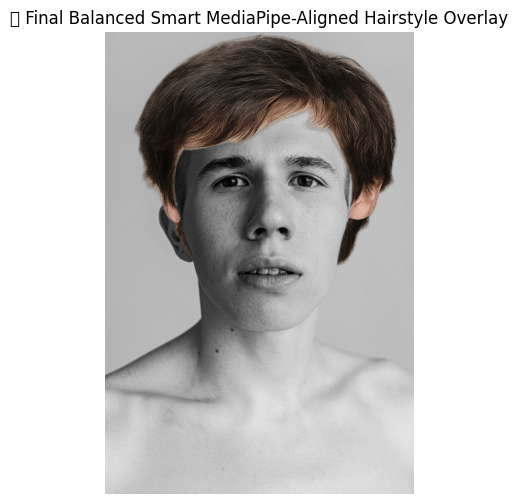

In [5]:
# Install dependencies
!pip install mediapipe opencv-python pillow

# Imports
import cv2
import mediapipe as mp
import numpy as np
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt

# Load image
image_path = "AR_project_backup/face_img.jpg"
image = cv2.imread(image_path)
if image is None:
    raise FileNotFoundError(f"Image '{image_path}' not found.")
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Initialize MediaPipe FaceMesh
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(static_image_mode=True)

# Detect facial landmarks
results = face_mesh.process(rgb_image)
if not results.multi_face_landmarks:
    raise ValueError("No face detected in the image.")

face_landmarks = results.multi_face_landmarks[0]
coords = [(int(lm.x * image.shape[1]), int(lm.y * image.shape[0])) for lm in face_landmarks.landmark]

# Load hairstyle image
hair_png = Image.open("hairstyle2.png").convert("RGBA")
base_img = Image.open(image_path).convert("RGBA")

# Forehead landmarks
center_top = coords[10]
left_temple = coords[127]
right_temple = coords[356]

# Calculate dynamic scaling and rotation
forehead_width = int(np.linalg.norm(np.array(right_temple) - np.array(left_temple)))
hair_width = int(forehead_width * 2.0)  # Balanced width scaling factor
hair_height = int(hair_width * hair_png.height / hair_png.width * 0.8)  # Slight height reduction

dx = right_temple[0] - left_temple[0]
dy = right_temple[1] - left_temple[1]
angle = np.degrees(np.arctan2(dy, dx))

# Resize and rotate hairstyle
resized_hair = hair_png.resize((hair_width, hair_height)).rotate(-angle, expand=True)

# Blur alpha channel for soft edges
blurred_alpha = resized_hair.split()[3].filter(ImageFilter.GaussianBlur(radius=2))
soft_hair = resized_hair.copy()
soft_hair.putalpha(blurred_alpha)

# Final placement adjustments for balance
adjustment_x = -20  # Shift left to reduce right-side bulge
adjustment_y = -100  # Move up to align with forehead

x_offset = center_top[0] - hair_width // 2 + adjustment_x
y_offset = center_top[1] - hair_height // 2 + adjustment_y

# Boundary checks
x_offset = max(0, x_offset)
y_offset = max(0, y_offset)
x_end = min(base_img.width, x_offset + resized_hair.width)
y_end = min(base_img.height, y_offset + resized_hair.height)

# Crop overlay to fit image boundaries
resized_hair = resized_hair.crop((0, 0, x_end - x_offset, y_end - y_offset))

# Create overlay layer and paste hairstyle
overlay_layer = Image.new("RGBA", base_img.size)
overlay_layer.paste(soft_hair, (x_offset, y_offset), mask=soft_hair)

# 📏 Evaluation Metrics Functions
def compute_landmark_alignment_error(center_top, overlay_position, overlay_size):
    overlay_center_x = overlay_position[0] + overlay_size[0] // 2
    overlay_center_y = overlay_position[1] + overlay_size[1] // 2
    lae = np.linalg.norm(np.array(center_top) - np.array([overlay_center_x, overlay_center_y]))
    return lae

def compute_overlay_coverage_score(coords, overlay_position, overlay_size):
    forehead_x = [coords[10][0], coords[338][0], coords[127][0], coords[356][0]]
    forehead_y = [coords[10][1], coords[338][1], coords[127][1], coords[356][1]]
    forehead_box = [min(forehead_x), min(forehead_y), max(forehead_x), max(forehead_y)]

    overlay_box = [overlay_position[0], overlay_position[1],
                   overlay_position[0] + overlay_size[0], overlay_position[1] + overlay_size[1]]

    ix = max(0, min(forehead_box[2], overlay_box[2]) - max(forehead_box[0], overlay_box[0]))
    iy = max(0, min(forehead_box[3], overlay_box[3]) - max(forehead_box[1], overlay_box[1]))
    intersection_area = ix * iy
    forehead_area = (forehead_box[2] - forehead_box[0]) * (forehead_box[3] - forehead_box[1])

    return intersection_area / forehead_area if forehead_area > 0 else 0

def compute_boundary_overflow_rate(overlay_position, overlay_size, base_image_size):
    overflow_x = max(0, overlay_position[0] + overlay_size[0] - base_image_size[0])
    overflow_y = max(0, overlay_position[1] + overlay_size[1] - base_image_size[1])
    overflow_area = overflow_x * overlay_size[1] + overflow_y * overlay_size[0]
    total_area = overlay_size[0] * overlay_size[1]
    return overflow_area / total_area if total_area > 0 else 0

# Calculate metrics
lae = compute_landmark_alignment_error(center_top, (x_offset, y_offset), (resized_hair.width, resized_hair.height))
ocs = compute_overlay_coverage_score(coords, (x_offset, y_offset), (resized_hair.width, resized_hair.height))
bor = compute_boundary_overflow_rate((x_offset, y_offset), (resized_hair.width, resized_hair.height), base_img.size)

# 📈 Display Metrics
print(f"📏 Landmark Alignment Error (LAE): {lae:.2f} pixels")
print(f"📐 Overlay Coverage Score (OCS): {ocs * 100:.2f}% of forehead covered")
print(f"🚫 Boundary Overflow Rate (BOR): {bor * 100:.2f}% overlay out of bounds")

# Final composite
final = Image.alpha_composite(base_img, overlay_layer)

# Show final result
plt.figure(figsize=(6, 6))
plt.imshow(final)
plt.axis('off')
plt.title("🎯 Final Balanced Smart MediaPipe-Aligned Hairstyle Overlay")
plt.show()



In [6]:
pip install mediapipe opencv-python pillow matplotlib pandas


Saving face_img.jpg to face_img (2).jpg


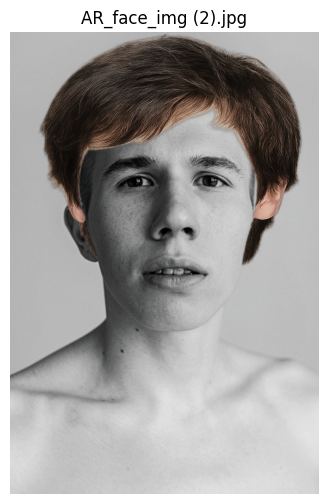


✅ Processing complete! Download your results below:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# Install dependencies
!pip install mediapipe opencv-python pillow matplotlib pandas

# Imports
import cv2
import mediapipe as mp
import numpy as np
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt
import pandas as pd
import os
from google.colab import files

# Upload multiple images manually
uploaded = files.upload()
image_files = list(uploaded.keys())

# Create output directory
output_folder = "AR_overlay_results"
os.makedirs(output_folder, exist_ok=True)

# Initialize MediaPipe FaceMesh
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(static_image_mode=True)

# Metrics Storage
results_list = []

# Process Each Uploaded Image
for image_file in image_files:
    image = cv2.imdecode(np.frombuffer(uploaded[image_file], np.uint8), cv2.IMREAD_COLOR)
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    results = face_mesh.process(rgb_image)

    if not results.multi_face_landmarks:
        print(f"⚠️ No face detected in {image_file}. Skipping...")
        continue

    face_landmarks = results.multi_face_landmarks[0]
    coords = [(int(lm.x * image.shape[1]), int(lm.y * image.shape[0])) for lm in face_landmarks.landmark]

    hair_png = Image.open("hairstyle2.png").convert("RGBA")  # Upload this file too
    base_img = Image.open(image_file).convert("RGBA")

    center_top = coords[10]
    left_temple = coords[127]
    right_temple = coords[356]

    forehead_width = int(np.linalg.norm(np.array(right_temple) - np.array(left_temple)))
    hair_width = int(forehead_width * 2.0)
    hair_height = int(hair_width * hair_png.height / hair_png.width * 0.8)

    dx = right_temple[0] - left_temple[0]
    dy = right_temple[1] - left_temple[1]
    angle = np.degrees(np.arctan2(dy, dx))

    resized_hair = hair_png.resize((hair_width, hair_height)).rotate(-angle, expand=True)
    blurred_alpha = resized_hair.split()[3].filter(ImageFilter.GaussianBlur(radius=2))
    soft_hair = resized_hair.copy()
    soft_hair.putalpha(blurred_alpha)

    adjustment_x = -20
    adjustment_y = -100
    x_offset = center_top[0] - hair_width // 2 + adjustment_x
    y_offset = center_top[1] - hair_height // 2 + adjustment_y

    x_offset = max(0, x_offset)
    y_offset = max(0, y_offset)
    x_end = min(base_img.width, x_offset + resized_hair.width)
    y_end = min(base_img.height, y_offset + resized_hair.height)
    resized_hair = resized_hair.crop((0, 0, x_end - x_offset, y_end - y_offset))

    overlay_layer = Image.new("RGBA", base_img.size)
    overlay_layer.paste(soft_hair, (x_offset, y_offset), mask=soft_hair)
    final = Image.alpha_composite(base_img, overlay_layer)
    plt.figure(figsize=(6, 6))
    plt.imshow(final)
    plt.axis('off')
    plt.title(f"AR_{image_file}")
    plt.show()
    # Visualize the Final Overlay




    # Save Final Image
    final_output_path = os.path.join(output_folder, f"AR_{image_file}")
    if final_output_path.lower().endswith(('.jpg', '.jpeg')):
       final.convert('RGB').save(final_output_path)
    else:
       final.save(final_output_path)


    # Evaluation Metrics
    def compute_la(center_top, overlay_pos, overlay_size):
        overlay_center_x = overlay_pos[0] + overlay_size[0] // 2
        overlay_center_y = overlay_pos[1] + overlay_size[1] // 2
        return np.linalg.norm(np.array(center_top) - np.array([overlay_center_x, overlay_center_y]))

    def compute_ocs(coords, overlay_pos, overlay_size):
        forehead_x = [coords[10][0], coords[338][0], coords[127][0], coords[356][0]]
        forehead_y = [coords[10][1], coords[338][1], coords[127][1], coords[356][1]]
        forehead_box = [min(forehead_x), min(forehead_y), max(forehead_x), max(forehead_y)]
        overlay_box = [overlay_pos[0], overlay_pos[1],
                       overlay_pos[0] + overlay_size[0], overlay_pos[1] + overlay_size[1]]
        ix = max(0, min(forehead_box[2], overlay_box[2]) - max(forehead_box[0], overlay_box[0]))
        iy = max(0, min(forehead_box[3], overlay_box[3]) - max(forehead_box[1], overlay_box[1]))
        intersection_area = ix * iy
        forehead_area = (forehead_box[2] - forehead_box[0]) * (forehead_box[3] - forehead_box[1])
        return intersection_area / forehead_area if forehead_area > 0 else 0

    def compute_bor(overlay_pos, overlay_size, base_size):
        overflow_x = max(0, overlay_pos[0] + overlay_size[0] - base_size[0])
        overflow_y = max(0, overlay_pos[1] + overlay_size[1] - base_size[1])
        overflow_area = overflow_x * overlay_size[1] + overflow_y * overlay_size[0]
        total_area = overlay_size[0] * overlay_size[1]
        return overflow_area / total_area if total_area > 0 else 0

    lae = compute_la(center_top, (x_offset, y_offset), (resized_hair.width, resized_hair.height))
    ocs = compute_ocs(coords, (x_offset, y_offset), (resized_hair.width, resized_hair.height))
    bor = compute_bor((x_offset, y_offset), (resized_hair.width, resized_hair.height), base_img.size)

    results_list.append({
        "Image": image_file,
        "LAE (pixels)": round(lae, 2),
        "OCS (%)": round(ocs * 100, 2),
        "BOR (%)": round(bor * 100, 2)
    })

# Save Metrics to CSV
metrics_df = pd.DataFrame(results_list)
csv_path = os.path.join(output_folder, "AR_overlay_metrics.csv")
metrics_df.to_csv(csv_path, index=False)

print(f"\n✅ Processing complete! Download your results below:")

# Download results as a zip
import shutil
shutil.make_archive("AR_overlay_results", 'zip', output_folder)
files.download("AR_overlay_results.zip")
files.download(csv_path)



In [11]:
# Install dependencies (run these in terminal if not already installed)
# pip install mediapipe opencv-python pillow numpy

import cv2
import mediapipe as mp
import numpy as np
from PIL import Image, ImageFilter

# Load Hairstyle Image
hair_png = Image.open("hairstyle2.png").convert("RGBA")

# Initialize MediaPipe FaceMesh
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(static_image_mode=False, max_num_faces=1, min_detection_confidence=0.5)

# Open Webcam
cap = cv2.VideoCapture(0)

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    results = face_mesh.process(rgb_frame)

    if results.multi_face_landmarks:
        face_landmarks = results.multi_face_landmarks[0]
        coords = [(int(lm.x * frame.shape[1]), int(lm.y * frame.shape[0])) for lm in face_landmarks.landmark]

        # Facial Landmarks for forehead region
        center_top = coords[10]
        left_temple = coords[127]
        right_temple = coords[356]

        # Compute size and rotation
        forehead_width = int(np.linalg.norm(np.array(right_temple) - np.array(left_temple)))
        hair_width = int(forehead_width * 2.0)
        hair_height = int(hair_width * hair_png.height / hair_png.width * 0.8)

        dx = right_temple[0] - left_temple[0]
        dy = right_temple[1] - left_temple[1]
        angle = np.degrees(np.arctan2(dy, dx))

        # Resize and rotate hairstyle
        resized_hair = hair_png.resize((hair_width, hair_height)).rotate(-angle, expand=True)
        blurred_alpha = resized_hair.split()[3].filter(ImageFilter.GaussianBlur(radius=1))
        soft_hair = resized_hair.copy()
        soft_hair.putalpha(blurred_alpha)

        # Calculate placement
        adjustment_x = -20
        adjustment_y = -100
        x_offset = center_top[0] - hair_width // 2 + adjustment_x
        y_offset = center_top[1] - hair_height // 2 + adjustment_y

        # Boundary checks
        x_offset = max(0, x_offset)
        y_offset = max(0, y_offset)

        # Convert frame to PIL Image for overlay
        base_img = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)).convert("RGBA")
        overlay_layer = Image.new("RGBA", base_img.size)
        overlay_layer.paste(soft_hair, (x_offset, y_offset), mask=soft_hair)

        final = Image.alpha_composite(base_img, overlay_layer)
        frame = cv2.cvtColor(np.array(final.convert("RGB")), cv2.COLOR_RGB2BGR)

    cv2.imshow('Real-Time AR Hairstyle Overlay', frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()


In [14]:
import os

# Create required folder structure
!mkdir -p face_dataset/images/test
!mkdir -p face_dataset/labels/test

# Move your image into the dataset structure
!cp AR_project_backup/face_img.jpg face_dataset/images/test/

# Create dummy label (1 bounding box, class 0, centered, 50% width & height)
with open("face_dataset/labels/test/face_img.txt", "w") as f:
    f.write("0 0.5 0.5 0.5 0.5")  # [class x_center y_center width height] in normalized format


In [17]:
yaml_content = """
path: face_dataset
train: images/test
val: images/test
test: images/test
names:
  0: face
"""

with open("face_dataset.yaml", "w") as f:
    f.write(yaml_content)

print("✅ Fixed YAML created with 'train' key.")


✅ Fixed YAML created with 'train' key.


In [21]:
# 🟢 Step 1: Get detection result
results = model("AR_project_backup/face_img.jpg")[0]  # ✅ Access the first item

# 🟢 Step 2: Extract bounding box (xyxy) of first detected object
x1, y1, x2, y2 = results.boxes.xyxy[0].cpu().numpy()

# 🟢 Step 3: Convert to YOLO format (x_center, y_center, width, height), normalized
img = cv2.imread("AR_project_backup/face_img.jpg")
h, w = img.shape[:2]

x_center = ((x1 + x2) / 2) / w
y_center = ((y1 + y2) / 2) / h
box_width = (x2 - x1) / w
box_height = (y2 - y1) / h

# 🟢 Step 4: Save corrected label in YOLO format
with open("face_dataset/labels/test/face_img.txt", "w") as f:
    f.write(f"0 {x_center:.6f} {y_center:.6f} {box_width:.6f} {box_height:.6f}")

print("✅ Corrected YOLO label saved.")




image 1/1 /content/AR_project_backup/face_img.jpg: 640x448 1 person, 48.8ms
Speed: 2.6ms preprocess, 48.8ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 448)
✅ Corrected YOLO label saved.


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128311 (\N{LARGE BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


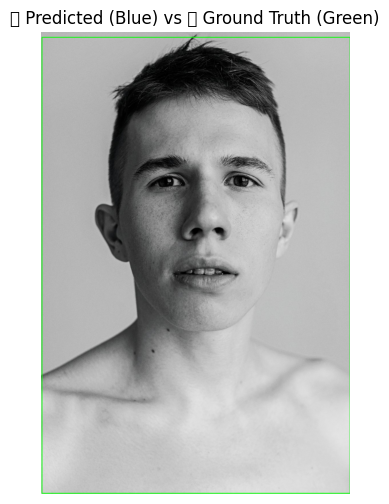

In [23]:
import matplotlib.pyplot as plt

# 1. Load image
img = cv2.imread("AR_project_backup/face_img.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]

# 2. Draw predicted box
pred_box = results.boxes.xyxy[0].cpu().numpy().astype(int)
x1, y1, x2, y2 = pred_box
cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)  # blue = predicted

# 3. Draw label box from YOLO label file
with open("face_dataset/labels/test/face_img.txt") as f:
    cls, xc, yc, bw, bh = map(float, f.readline().split())
    x1_gt = int((xc - bw / 2) * w)
    y1_gt = int((yc - bh / 2) * h)
    x2_gt = int((xc + bw / 2) * w)
    y2_gt = int((yc + bh / 2) * h)
    cv2.rectangle(img, (x1_gt, y1_gt), (x2_gt, y2_gt), (0, 255, 0), 2)  # green = ground truth

# 4. Show image
plt.figure(figsize=(8,6))
plt.imshow(img)
plt.title("🔷 Predicted (Blue) vs 🟢 Ground Truth (Green)")
plt.axis('off')
plt.show()


In [24]:
print("Predicted class:", results.boxes.cls[0].item())  # Should be 0


Predicted class: 0.0


In [25]:
metrics = model.val(data="face_dataset.yaml", conf=0.001)


Ultralytics 8.3.154 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1586.9±0.0 MB/s, size: 201.3 KB)


val: Scanning /content/face_dataset/labels/test... 1 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1/1 [00:00<00:00, 573.38it/s]

val: New cache created: /content/face_dataset/labels/test.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:00<00:00,  4.77it/s]


                   all          1          1          1          1      0.995      0.995
                person          1          1          1          1      0.995      0.995
Speed: 0.7ms preprocess, 58.2ms inference, 0.0ms loss, 11.2ms postprocess per image
Results saved to runs/detect/val4


In [26]:
print("mAP@0.5:", metrics.box.map50)
print("mAP@0.5:0.95:", metrics.box.map)


mAP@0.5: 0.995
mAP@0.5:0.95: 0.9949999999999999


In [27]:
from google.colab import files
uploaded = files.upload()  # Upload multiple JPG/PNG face images


Saving AR_overlay pics.zip to AR_overlay pics.zip


In [28]:
import os
os.makedirs("face_dataset/images/test", exist_ok=True)

# Move all uploaded files to the correct directory
for filename in uploaded.keys():
    os.rename(filename, f"face_dataset/images/test/{filename}")


In [30]:
import os

valid_exts = [".jpg", ".jpeg", ".png", ".bmp"]

for image_name in os.listdir(image_dir):
    if not any(image_name.lower().endswith(ext) for ext in valid_exts):
        print(f"⏭️ Skipping non-image file: {image_name}")
        continue  # Skip zip or unsupported files

    image_path = os.path.join(image_dir, image_name)
    results = model(image_path)[0]

    if len(results.boxes):
        h, w = cv2.imread(image_path).shape[:2]
        label_path = os.path.join(label_dir, image_name.rsplit(".", 1)[0] + ".txt")
        with open(label_path, "w") as f:
            for box in results.boxes.xyxy:
                x1, y1, x2, y2 = box.cpu().numpy()
                x_center = ((x1 + x2) / 2) / w
                y_center = ((y1 + y2) / 2) / h
                bw = (x2 - x1) / w
                bh = (y2 - y1) / h
                f.write(f"0 {x_center:.6f} {y_center:.6f} {bw:.6f} {bh:.6f}\n")



⏭️ Skipping non-image file: AR_overlay pics.zip

image 1/1 /content/face_dataset/images/test/face_img.jpg: 640x448 1 person, 47.3ms
Speed: 15.2ms preprocess, 47.3ms inference, 2.8ms postprocess per image at shape (1, 3, 640, 448)


In [32]:
import os
os.listdir()



['.config',
 'hairstyle2 (1).png',
 'yolov8l.pt',
 'results_face_img.jpg',
 'AR_Hairstyle_TryOn_Backup.zip',
 'runs',
 'AR_overlay_results',
 'AR_project_backup',
 'face_dataset',
 'face_img (2).jpg',
 'face_dataset.yaml',
 'AR_overlay_results.zip',
 'hairstyle2.png',
 'face_img.jpg',
 'face_img (1).jpg',
 'sample_data']

In [41]:
import os
import zipfile

# Auto-detect first .zip file
zip_files = [f for f in os.listdir() if f.endswith(".zip")]
if zip_files:
    zip_path = zip_files[0]
    extract_to = "face_dataset/images/test"
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print(f"✅ Extracted: {zip_path} to {extract_to}")
else:
    print("❌ No ZIP file found.")


✅ Extracted: AR_Hairstyle_TryOn_Backup.zip to face_dataset/images/test


In [42]:
from ultralytics import YOLO
import cv2
import os

model = YOLO("yolov8l.pt")  # or your own .pt if trained

image_dir = "face_dataset/images/test"
label_dir = "face_dataset/labels/test"
os.makedirs(label_dir, exist_ok=True)

valid_exts = [".jpg", ".jpeg", ".png"]

for image_name in os.listdir(image_dir):
    if not any(image_name.lower().endswith(ext) for ext in valid_exts):
        print("⏭️ Skipping non-image file:", image_name)
        continue

    image_path = os.path.join(image_dir, image_name)
    results = model(image_path)[0]

    if len(results.boxes):
        h, w = cv2.imread(image_path).shape[:2]
        label_path = os.path.join(label_dir, image_name.rsplit('.', 1)[0] + ".txt")

        with open(label_path, "w") as f:
            for box in results.boxes.xyxy:
                x1, y1, x2, y2 = box.cpu().numpy()
                x_center = ((x1 + x2) / 2) / w
                y_center = ((y1 + y2) / 2) / h
                bw = (x2 - x1) / w
                bh = (y2 - y1) / h
                f.write(f"0 {x_center:.6f} {y_center:.6f} {bw:.6f} {bh:.6f}\n")

print("✅ All labels saved to face_dataset/labels/test/")


⏭️ Skipping non-image file: AR_overlay pics.zip
⏭️ Skipping non-image file: AR_project_backup

image 1/1 /content/face_dataset/images/test/face_img.jpg: 640x448 1 person, 46.2ms
Speed: 2.7ms preprocess, 46.2ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 448)
✅ All labels saved to face_dataset/labels/test/


In [43]:
yaml_content = """
path: face_dataset
train: images/test
val: images/test
test: images/test
names:
  0: face
"""

with open("face_dataset.yaml", "w") as f:
    f.write(yaml_content)

print("✅ YAML written: face_dataset.yaml")


✅ YAML written: face_dataset.yaml


In [44]:
!rm -rf face_dataset/labels/test.cache


In [47]:
metrics = model.val(data="face_dataset.yaml", conf=0.001)
print("📊 mAP@0.5:", metrics.box.map50)
print("📊 mAP@0.5:0.95:", metrics.box.map)


Ultralytics 8.3.154 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1222.3±581.9 MB/s, size: 3323.2 KB)


val: Scanning /content/face_dataset/labels/test/AR_project_backup.cache... 1 images, 5 backgrounds, 0 corrupt: 100%|██████████| 6/6 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:01<00:00,  1.39s/it]


                   all          6          1      0.328          1      0.497      0.497
                person          1          1      0.328          1      0.497      0.497
Speed: 0.3ms preprocess, 54.6ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to runs/detect/val6
📊 mAP@0.5: 0.4975
📊 mAP@0.5:0.95: 0.49749999999999994
